# Model Training

Every ML model of the project, from simple to complex, on the same CV folds and metrics as the baselines. Each model's default settings are scored first, then Optuna tries more settings. Every trial is logged to `training_runs.parquet`; a tuning run already in the log is read back instead of trained again. The champion is the model with the best mean CV score; it is refitted on the whole training set and saved for `/ml-offline-evaluation`. The test set is not used here.

**How to use this notebook.** The cells marked *Decision* hold the models and the training settings. To add a model, add it to `MODELS` (or run `/ml-model-training` again) and choose Run All: only new models are trained. Raw rows are never shown here.

## Setup

Finds the project root, loads the shared spec `ml_spec.yaml`, and checks the kernel. Run this cell first.

In [1]:
import os
import sys
from pathlib import Path

# The project root is the closest folder with ml_spec.yaml. Everything runs from there.
here = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in here if (p / "ml_spec.yaml").is_file()), Path.cwd())
os.chdir(ROOT)
# The project's own code (src) comes from this folder, also in an experiment's worktree, where the editable
# install in .venv would point to the main project.
sys.path.insert(0, str(ROOT))

# Shared code from the ML project skills
sys.path.insert(0, r"/Users/ani/.claude/skills/ml-model-training/scripts")
import ml_common
import nb_common
try:  # MLflow tracking, in the ML project skills: keeps a copy of each chart for the stage's run
    import tracking
    tracking.capture_figures()
except ImportError:
    tracking = None

SPEC_PATH = str(ROOT / "ml_spec.yaml")
spec = ml_common.migrate(ml_common.load(SPEC_PATH)) if os.path.exists(SPEC_PATH) else ml_common.template()
PATHS = ml_common.project_paths(spec, str(ROOT))
NOTEBOOK = os.path.join(PATHS["notebooks"], "08_training.ipynb")
STAGE = "training"

print("Project root:", ROOT)
print("Python:", sys.executable)
if (ROOT / ".venv").is_dir() and Path(sys.prefix).resolve() != (ROOT / ".venv").resolve():
    print("Warning: this kernel is not the project's .venv. Choose 'Select Kernel' and pick the project kernel.")

Project root: /Users/ani/Projects/16_weather_prediction
Python: /Users/ani/Projects/16_weather_prediction/.venv/bin/python


In [2]:
import datetime as dt
import importlib
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import model_core
import split_core

sys.path.insert(0, str(ROOT))   # the project's own src package
import src.features as F
importlib.reload(F)

<module 'src.features' from '/Users/ani/Projects/16_weather_prediction/src/features.py'>

## What This Builds On

In [3]:
framing, business, split, features, baseline = (spec.get(k) or {} for k in ("framing", "business", "split", "features", "baseline"))
TASK_TYPE, TARGET = framing.get("task_type"), split.get("target")
FAMILY = model_core.task_family(TASK_TYPE)
CONFIG = F.load_config(spec)
INPUTS = F.feature_columns(CONFIG)
METRICS = baseline["metrics"]
PRIMARY = baseline["primary_label"]
HIGHER = model_core.HIGHER_IS_BETTER.get(model_core.all_metrics(METRICS)[0]["key"]) is not False
VERSION = model_core.data_version(spec)
reference, best_baseline = baseline.get("reference") or {}, baseline.get("best_non_ml") or {}
print(f"Task: {TASK_TYPE}. Target: {TARGET}. Inputs: {len(INPUTS)}. Metric: {PRIMARY} ({'higher' if HIGHER else 'lower'} is better)")
print(f"Reference: {reference.get('name')} {reference.get(PRIMARY)}. Best baseline: {best_baseline.get('name')} {best_baseline.get(PRIMARY)}")
print(f"V1 bar: {(framing.get('success') or {}).get('v1_bar')}")
print(f"Features and split version: {VERSION}")
blockers = ml_common.modelling_blockers(spec)
print("Modelling may start." if not blockers else "Not ready for modelling: " + "; ".join(blockers))

Task: forecasting. Target: temperature_2m_max. Inputs: 28. Metric: mae (lower is better)
Reference: naive 2.5156. Best baseline: naive 2.5156
V1 bar: MAE at least 10% lower than the best simple baseline (persistence, seasonal naive, or moving average) on CV, and still lower than it on the test set
Features and split version: b77122beb607
Modelling may start.


## Load the Training Rows and Folds

In [4]:
data = pd.read_parquet(features["files"]["train"]).reset_index(drop=True)
folds = split_core.cv_splits(data, split)
row_id = split.get("row_id_col") or "row_id"
print(f"Training rows: {len(data):,}. Folds: {len(folds)}, validation rows per fold: {[len(v) for _, v in folds]}")

Training rows: 41,150. Folds: 4, validation rows per fold: [4550, 4550, 4550, 4550]


## Models

A linear model and gradient boosting show how much a complex model adds over a simple one, both against persistence (CV MAE 2.52), which the V1 bar requires beating by 10% (MAE 2.26 or lower). Iteration 1 (V2) retrains both on target encoded city and country, and carries the V1 LightGBM forward with its settings fixed.

Quick tuning (20 trials) for both. Ridge has one main setting; for LightGBM the tuning curve shows whether a thorough search would help.

*Each model has a `name` (unique), a `type` (logistic, ridge, tree, random_forest, hist_gbm, lightgbm, xgboost, catboost), `params` (fixed settings, never tuned), `class_weight` (`balanced` or None), `tuning` (`n_trials`, 1 for the default settings only, and `timeout_minutes`), optional `inputs` (a subset of the feature inputs, when the model must use only some of them), and a `reason`. To add a model, append it here and choose Run All; models already trained with the same settings are read back from the run log.*

In [5]:
# Decision
MODELS = [
    {
        'name': 'ridge',
        'type': 'ridge',
        'params': {},
        'class_weight': None,
        'tuning': {'n_trials': 20, 'timeout_minutes': 10},
        'reason': 'The simple model first: it shows whether the lag, calendar, and location features beat persistence without any complexity, and it is easy to explain.',
    },
    {
        'name': 'lightgbm',
        'type': 'lightgbm',
        'params': {},
        'class_weight': None,
        'tuning': {'n_trials': 20, 'timeout_minutes': 10},
        'reason': 'Gradient boosting can learn interactions such as latitude with day of year, where seasons flip between hemispheres.',
    },
    {
        'name': 'lightgbm_iter0',
        'type': 'lightgbm',
        'params': {
            'colsample_bytree': 0.881961,
            'learning_rate': 0.012874,
            'min_child_samples': 88,
            'n_estimators': 700,
            'num_leaves': 40,
            'reg_lambda': 0.004712,
            'subsample': 0.533786,
            'subsample_freq': 1,
        },
        'class_weight': None,
        'tuning': {'n_trials': 1},
        'inputs': [
            'apparent_temperature_max_lag_2d',
            'apparent_temperature_min_lag_2d',
            'city',
            'date_dayofyear',
            'date_month',
            'elevation',
            'latitude',
            'log_elevation',
            'longitude',
            'precipitation_sum_lag_2d',
            'shortwave_radiation_sum_lag_2d',
            'snowfall_sum_lag_2d',
            'sunshine_duration_lag_2d',
            'temp_max_change_1d',
            'temp_max_vs_28d_mean',
            'temperature_2m_max_lag_2d',
            'temperature_2m_max_lag_364d',
            'temperature_2m_max_lag_3d',
            'temperature_2m_max_lag_7d',
            'temperature_2m_max_roll_28d_mean_shift_2d',
            'temperature_2m_max_roll_7d_mean_shift_2d',
            'temperature_2m_mean_lag_2d',
            'temperature_2m_min_lag_2d',
            'weather_code_lag_2d',
            'wind_direction_10m_dominant_lag_2d',
            'wind_gusts_10m_max_lag_2d',
            'wind_speed_10m_max_lag_2d',
        ],
        'reason': 'The champion of iteration 0, carried forward with its tuned settings fixed, so it is scored on the same folds and features as the new models. Its city is target encoded under the V2 features, so it isolates the encoding effect at fixed settings.',
    },
]

## Training Settings

*`seed` makes the tuning repeatable. `selection` is `best_mean`: the champion is the model with the best mean CV score on the primary metric.*

In [6]:
# Decision
TRAINING = {'seed': 42, 'selection': 'best_mean'}

## Train and Tune

New tuning runs are trained and appended to the run log. Runs already in the log are read back.

In [7]:
names = [m["name"] for m in MODELS]
assert len(names) == len(set(names)), "Every model needs a unique name."
for m in MODELS:
    assert m["type"] in model_core.ML_MODELS, f"{m['name']}: unknown type {m['type']}"
    assert model_core.available(m["type"]), f"{m['name']}: the package for {m['type']} is not installed (uv add {model_core.ML_MODELS[m['type']][1]})"
    model_core.model_config(m, CONFIG)   # checks that a model's inputs subset is in the feature set
RUNS = os.path.join(PATHS["data_processed"], "training_runs.parquet")
OOF = os.path.join(PATHS["data_processed"], "training_oof_predictions.parquet")
log = model_core.RunLog(RUNS)
keys = {}
for m in MODELS:
    key = model_core.study_key(m, METRICS, VERSION)
    keys[m["name"]] = key
    if log.has_study(key):
        print(f"{m['name']}: read back from the run log (study {key})")
        continue
    records, oof = model_core.tune(m, data, INPUTS, TARGET, folds, METRICS, TASK_TYPE, CONFIG, seed=TRAINING["seed"])
    log.append(m, key, VERSION, records)
    oof = oof.assign(model=m["name"], study=key, **{row_id: data[row_id].values[oof["position"]]}).drop(columns="position")
    old = pd.read_parquet(OOF) if os.path.exists(OOF) else pd.DataFrame()
    keep = old[old["model"] != m["name"]] if len(old) else old
    pd.concat([keep, oof], ignore_index=True).to_parquet(OOF, index=False)
    print(f"{m['name']}: {len(records)} trials logged")

/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


ridge trial 0: mae 2.2441 (1.8s)


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behavi

/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


...

/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


lightgbm_iter0 trial 0: mae 2.1637 (27.2s)
lightgbm_iter0: 1 trials logged


## Leaderboard

The best trial of every model, with the baselines from `07_baseline.ipynb`, on the same folds and metric. `vs reference` is the improvement over the reference in %, positive when better.

,model,type,mae,std,trials,minutes,kind,vs reference %
0,lightgbm_iter0,lightgbm,2.163734,0.233525,1.0,0.5,ml,14.0
1,lightgbm,lightgbm,2.164778,0.233851,20.0,10.5,ml,13.9
2,ridge,ridge,2.244040,0.244693,20.0,0.2,ml,10.8
3,naive,non ML,2.515648,0.268585,NaN,NaN,baseline,0.0
4,moving_average,non ML,2.774013,0.313272,NaN,NaN,baseline,-10.3
5,seasonal_naive,non ML,3.327011,0.523032,NaN,NaN,baseline,-32.3


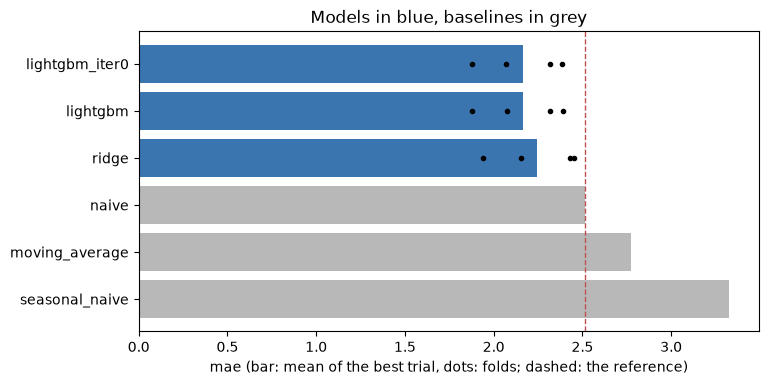

In [8]:
runs = log.load()
runs = runs[runs["study"].isin(keys.values())]
pick = (lambda g: g.loc[g["primary_mean"].idxmax()]) if HIGHER else (lambda g: g.loc[g["primary_mean"].idxmin()])
best = runs.groupby("model", sort=False).apply(pick, include_groups=False).reset_index()
best["trials"] = runs.groupby("model", sort=False).size().reindex(best["model"]).values
best["minutes"] = (runs.groupby("model", sort=False)["seconds"].sum() / 60).round(1).reindex(best["model"]).values
board = best[["model", "type", "primary_mean", "primary_std", "trials", "minutes"]].assign(kind="ml")
bl_runs = pd.read_parquet(baseline["files"]["cv_results"])
bl_runs = bl_runs[bl_runs["model"].isin([b["name"] for b in baseline.get("models") or []])]   # current baselines only
bl = bl_runs.groupby("model", sort=False)[PRIMARY].agg(["mean", "std"]).reset_index()
bl["model"] = [n if n not in keys else f"{n} (baseline)" for n in bl["model"]]
bl = bl.rename(columns={"mean": "primary_mean", "std": "primary_std"}).assign(kind="baseline", type="non ML")
board = pd.concat([board, bl], ignore_index=True)
ref = reference.get(PRIMARY)
if reference.get("name") in set(bl_runs["model"]):   # the exact value, not the rounded one in the spec
    ref = float(bl_runs.loc[bl_runs["model"] == reference["name"], PRIMARY].mean())
board["vs reference %"] = (((board.primary_mean - ref) if HIGHER else (ref - board.primary_mean)) / abs(ref) * 100).round(1) if ref else None
board = board.sort_values("primary_mean", ascending=not HIGHER).reset_index(drop=True)
display(board.rename(columns={"primary_mean": PRIMARY, "primary_std": "std"}))

fig, ax = plt.subplots(figsize=(8, 0.45 * len(board) + 1.2))
order = board.iloc[::-1]
for i, r in enumerate(order.itertuples()):
    ax.barh(i, r.primary_mean, color="#3b75af" if r.kind == "ml" else "#b8b8b8")
    if r.kind == "ml":
        vals = json.loads(best.set_index("model").loc[r.model, "folds"])
        ax.plot(vals, [i] * len(vals), "k.", markersize=6)
if ref:
    ax.axvline(ref, color="#c0504d", linestyle="--", linewidth=1)
ax.set_yticks(range(len(order)), order["model"])
ax.set_xlabel(PRIMARY + " (bar: mean of the best trial, dots: folds; dashed: the reference)")
ax.set_title("Models in blue, baselines in grey")
plt.show()

### Tuning History

The best score so far after each trial. A curve that is still rising at the end means more trials could help.

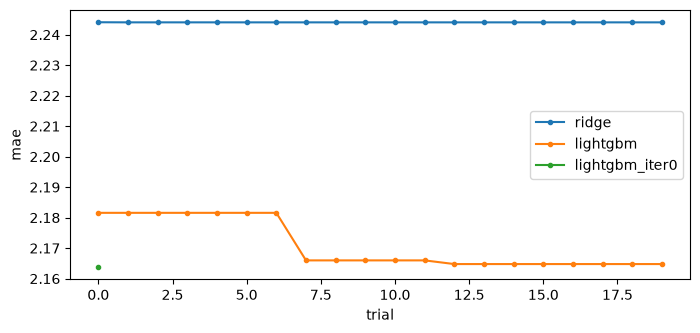

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, g in runs.groupby("model", sort=False):
    g = g.sort_values("trial")
    so_far = g["primary_mean"].cummax() if HIGHER else g["primary_mean"].cummin()
    ax.plot(g["trial"], so_far, marker=".", label=name)
ax.set_xlabel("trial")
ax.set_ylabel(PRIMARY)
ax.legend()
plt.show()

## Champion

The model with the best mean CV score. It is refitted on every training row (the gap and test rows are not used) and saved to the models folder for `/ml-offline-evaluation`.

In [10]:
ml_board = board[board.kind == "ml"]
champ_row = ml_board.iloc[0]
champ_model = next(m for m in MODELS if m["name"] == champ_row["model"])
champ_trial = best.set_index("model").loc[champ_row["model"]]
champion = {**champ_model, "params": json.loads(champ_trial["params"])}
print(f"Champion: {champion['name']} ({champion['type']}), {PRIMARY} {champ_row['primary_mean']:.4f} "
      f"(std {champ_row['primary_std']:.4f}), trial {int(champ_trial['trial'])}")
print("Settings: " + json.dumps(champion["params"]))
pipe = model_core.make_estimator(champion, FAMILY, CONFIG, data[TARGET])
pipe.fit(data[INPUTS], data[TARGET])
os.makedirs(PATHS["models"], exist_ok=True)
MODEL_PATH = os.path.join(PATHS["models"], f"champion_{champion['name']}.joblib")
SERIALIZATION = model_core.save_model(pipe, MODEL_PATH)   # loads with joblib.load, without the skills
print(f"Saved {ml_common.relpath(MODEL_PATH, str(ROOT))} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

Champion: lightgbm_iter0 (lightgbm), mae 2.1637 (std 0.2335), trial 0
Settings: {"colsample_bytree": 0.881961, "learning_rate": 0.012874, "min_child_samples": 88, "n_estimators": 700, "num_leaves": 40, "reg_lambda": 0.004712, "subsample": 0.533786, "subsample_freq": 1}


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Saved models/champion_lightgbm_iter0.joblib (2.6 MB)


## Checks

1. **Leakage:** a score that is too good to be true usually means a feature leaks the outcome.
2. **Against the baselines:** the champion should beat the reference and the best baseline, and meet the V1 bar.
3. **Overfitting:** the champion's score on its own training rows against its CV score.
4. **Stability:** how much the score moves between folds.

In [11]:
import re
problems = []
champ_metrics = json.loads(champ_trial["metrics"])
if FAMILY == "binary" and champ_metrics.get("roc_auc", 0) > 0.97:
    problems.append(f"The champion's AUC is {champ_metrics['roc_auc']:.3f}, which is suspiciously high. Check the features for leakage.")
gain = champ_row["vs reference %"]
bb = best_baseline.get(PRIMARY)
beats = lambda a, b: a > b if HIGHER else a < b
if ref is not None and not beats(champ_row["primary_mean"], ref):
    problems.append("The champion does not beat the reference.")
if bb is not None and not beats(champ_row["primary_mean"], bb):
    problems.append(f"The champion does not beat the best baseline, {best_baseline.get('name')}.")
# The V1 bar, judged on CV from framing.success.v1_criteria (the text bar is shown for people, never parsed)
cv_scores = {str(n).replace(" (baseline)", ""): {PRIMARY: float(v)} for n, v in zip(board["model"], board["primary_mean"])}
v1_ctx = model_core.V1Context(spec, str(ROOT), "cv", champion, data, INPUTS, TARGET, FAMILY, CONFIG, folds, pipeline=pipe)
v1_cv = ml_common.v1_evaluate(spec, "cv", cv_scores, champion["name"], reference.get("name"),
                              model_core.run_v1_checks(v1_ctx), primary=PRIMARY)
print(f"V1 bar: {(framing.get('success') or {}).get('v1_bar') or 'not set'}")
print("V1 criteria on CV: " + ml_common.v1_summary(v1_cv))
for r in v1_cv["criteria"]:
    print(f"  {r['id']} ({r['kind']}): {r['status']}. {r['detail']}")
if v1_cv["status"] == "not_met":
    problems.append("The V1 bar is not met on CV: " + ", ".join(r["id"] for r in v1_cv["criteria"] if r["status"] == "fail") + ".")
elif v1_cv["status"] == "incomplete":
    problems.append("Some V1 criteria could not be judged: " + "; ".join(r["detail"] for r in v1_cv["criteria"] if r["status"] == "unavailable"))
v1_met = {"met": True, "not_met": False}.get(v1_cv["status"])

# Overfitting: score on the training rows of each fold against the validation rows
train_scores = []
for tr, va in folds:
    sample = tr if len(tr) <= 50_000 else np.random.default_rng(0).choice(tr, 50_000, replace=False)
    pred = model_core.fit_predict(champion, data.iloc[tr], data.iloc[sample], INPUTS, TARGET, FAMILY, CONFIG)
    m0 = model_core.all_metrics(METRICS)[0]
    groups = data.iloc[sample][m0["k_per"]].values if m0.get("k_per") else None
    train_scores.append(model_core.score_metric(m0, data.iloc[sample][TARGET].values, pred, groups,
                                                probabilistic=champion["type"] in model_core.PROBABILISTIC))
train_mean, cv_mean = float(np.mean(train_scores)), float(champ_row["primary_mean"])
print(f"Overfitting: {PRIMARY} on the training rows {train_mean:.4f}, on the validation rows {cv_mean:.4f}")
if CONFIG.get("high_cardinality"):
    print("Note: TargetEncoder columns are encoded with their own targets when a model scores its training rows, so "
          "the training score above is too high and is not used as an overfitting signal.")
elif cv_mean and abs(train_mean - cv_mean) / abs(cv_mean) > 0.3:
    problems.append(f"The champion scores {train_mean:.3f} on its training rows and {cv_mean:.3f} in CV: it may overfit. "
                    "Try stronger regularisation or fewer, simpler settings.")
if champ_row["primary_std"] and abs(champ_row["primary_std"]) > 0.2 * abs(cv_mean):
    problems.append("The champion's score varies a lot between folds.")
print("Problems: " + (" ".join(problems) if problems else "none found."))

V1 bar: MAE at least 10% lower than the best simple baseline (persistence, seasonal naive, or moving average) on CV, and still lower than it on the test set
V1 criteria on CV: met on cv (beats_best_baseline_cv pass)
  beats_best_baseline_cv (pct_over_reference): pass. +14.0% against naive, needs 10%.


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Overfitting: mae on the training rows 1.8890, on the validation rows 2.1637
Note: TargetEncoder columns are encoded with their own targets when a model scores its training rows, so the training score above is too high and is not used as an overfitting signal.
Problems: none found.


### Feature Importance

Permutation importance of the champion on the validation rows of the last fold: how much the score drops when one input is shuffled. A single input that dominates, or an input that should not matter, deserves a second look.

In [12]:
from sklearn.inspection import permutation_importance
tr, va = folds[-1]
fold_pipe = model_core.make_estimator(champion, FAMILY, CONFIG, data.iloc[tr][TARGET]).fit(data.iloc[tr][INPUTS], data.iloc[tr][TARGET])
va_rows = va if len(va) <= 20_000 else np.random.default_rng(0).choice(va, 20_000, replace=False)
scoring = "roc_auc" if FAMILY == "binary" else "neg_mean_absolute_error"
imp = permutation_importance(fold_pipe, data.iloc[va_rows][INPUTS], data.iloc[va_rows][TARGET], scoring=scoring,
                             n_repeats=3, random_state=0)
importance = pd.DataFrame({"feature": INPUTS, "importance": imp.importances_mean, "std": imp.importances_std})
importance = importance.sort_values("importance", ascending=False).reset_index(drop=True)
print(f"Score used: {scoring}")
display(importance.head(15).round(4))

/Users/ani/Projects/16_weather_prediction/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Score used: neg_mean_absolute_error


,feature,importance,std
0,temperature_2m_max_lag_2d,2.0137,0.0301
1,temperature_2m_max_roll_7d_mean_shift_2d,1.8307,0.0165
2,temperature_2m_max_roll_28d_mean_shift_2d,0.8304,0.0119
3,shortwave_radiation_sum_lag_2d,0.2034,0.0161
4,apparent_temperature_max_lag_2d,0.1279,0.0105
5,city,0.1078,0.0029
6,temperature_2m_mean_lag_2d,0.0848,0.0019
7,temperature_2m_max_lag_364d,0.0706,0.0043
8,temperature_2m_max_lag_7d,0.0624,0.0058
9,apparent_temperature_min_lag_2d,0.0388,0.0050


### Calibration

For classification: the champion's predicted probabilities against the observed rate, in ten groups of its out of fold predictions. Points on the diagonal mean the probabilities can be read as chances. Class weights push them away from it.

In [13]:
if FAMILY == "binary":
    oof_all = pd.read_parquet(OOF)
    co = oof_all[oof_all["model"] == champion["name"]].merge(data[[row_id, TARGET]], on=row_id)
    co["group"] = pd.qcut(co["prediction"].rank(method="first"), 10, labels=False)
    cal = co.groupby("group").agg(predicted=("prediction", "mean"), observed=(TARGET, "mean"), rows=(TARGET, "size"))
    display(cal.round(4))
    fig, ax = plt.subplots(figsize=(4, 4))
    lim = max(cal.predicted.max(), cal.observed.max()) * 1.05
    ax.plot([0, lim], [0, lim], color="#b8b8b8", linewidth=1)
    ax.plot(cal.predicted, cal.observed, marker="o", color="#3b75af")
    ax.set_xlabel("predicted")
    ax.set_ylabel("observed")
    ax.set_title("Calibration of the champion")
    plt.show()
else:
    print("Not a classification task, so there is no calibration check.")

Not a classification task, so there is no calibration check.


## Risks, Assumptions, Open Questions, and Decisions

In [14]:
# Decision
risks = []

assumptions = []

open_questions = []

decisions = [
    {
        'decision': 'Build ridge and LightGBM with quick tuning (20 trials each).',
        'reason': 'The user chose them; a simple and a complex model, compared on the same folds.',
    },
    {
        'decision': 'Iteration 1 (V2): retrain ridge and LightGBM (20 trials each) on target encoded city and country, plus lightgbm_iter0 with the V1 settings fixed.',
        'reason': 'The plan agreed in ml-iterate: compare the new encoding against the V1 champion on the same folds.',
    },
]

resolved_questions = []

## Write to the Spec

Replaces the `training` section of `ml_spec.yaml`. Offline evaluation reads the champion from there.

In [15]:
training_section = split_core.plain({
    "models": MODELS,
    "settings": TRAINING,
    "data_version": VERSION,
    "primary_label": PRIMARY,
    "leaderboard": board.to_dict("records"),
    "champion": {
        "name": champion["name"], "type": champion["type"], "params": champion["params"],
        "class_weight": champion.get("class_weight"), "inputs": champion.get("inputs"), "run_id": champ_trial["run_id"],
        PRIMARY: float(champ_row["primary_mean"]), "std": float(champ_row["primary_std"]),
        "vs_reference_pct": None if gain is None or pd.isna(gain) else float(gain),
        "beats_best_baseline": None if bb is None else bool(beats(champ_row["primary_mean"], bb)),
        "v1_bar_met": v1_met,
        "v1": v1_cv,
        "path": ml_common.relpath(MODEL_PATH, str(ROOT)),
        "serialization": SERIALIZATION,
    },
    "top_features": importance.head(10)[["feature", "importance"]].round(5).to_dict("records"),
    "files": {"runs": ml_common.relpath(RUNS, str(ROOT)), "oof_predictions": ml_common.relpath(OOF, str(ROOT)),
               "champion_model": ml_common.relpath(MODEL_PATH, str(ROOT))},
    "checks": {"problems": problems, "train_score": train_mean, "cv_score": cv_mean},
    "run_at": dt.datetime.now().replace(microsecond=0).isoformat(),
})
nb_common.write_stage(SPEC_PATH, "training", training_section, "ml-model-training", assumptions, open_questions, decisions,
                      replace=True)
not_found = nb_common.resolve_questions(SPEC_PATH, resolved_questions, "ml-model-training")
if not_found:
    print("These open question IDs were not found: " + ", ".join(map(str, not_found)))
nb_common.record_run(SPEC_PATH, STAGE, NOTEBOOK, "ml-model-training")
print(f"Wrote the training section of ml_spec.yaml. Champion: {champion['name']}.")

Wrote the training section of ml_spec.yaml. Champion: lightgbm_iter0.


## Log to MLflow

Logs this run to the project's experiment on the shared MLflow server: the settings, the metrics, the tables, and the charts above, read from what this notebook just wrote to the spec. The run is marked as the current one for this stage. When the server is not reachable, nothing is logged and the notebook still finishes.

In [16]:
MLFLOW_RUN = tracking.log_stage(SPEC_PATH, STAGE, NOTEBOOK, "ml-model-training") if tracking else None

Registered model '16-weather-prediction-champion' already exists. Creating a new version of this model...
Created version '2' of model '16-weather-prediction-champion'.


MLflow: candidate champion registered as 16-weather-prediction-champion version 2 (alias champion-v2) for V2; the alias 'champion' is unchanged until the version is promoted.


MLflow: logged the training run to ml/16-weather-prediction: http://127.0.0.1:5000/#/experiments/5/runs/97f98df0f43a4cfaaf7d4f782460643a


## Next Step

To try another model, run `/ml-model-training` again or add it to `MODELS` above. When the champion is good enough, run `/ml-offline-evaluation`, which scores it and the baselines on the test set once. Check progress with `/ml-status`.